# Numerical companion of Section 5 (optimized gradient methods)

This notebook contains the numerical computations behind Section 5 of *Accelerated gradient methods in unconstrained convex optimization* (d'Aspremont, Kunstner, Taylor); the symbolic verifications of the theorems are in `Section5.ipynb`. Worst-case guarantees are computed with [PEPit](https://pepit.readthedocs.io), which builds and solves the semidefinite reformulations of the performance estimation problems of Section 5.1 (see also the [SIAM OP26 mini-tutorial](https://github.com/PerformanceEstimation/Tutorial-SIAM-OP26)).

Throughout, $f\in\mathcal F_{0,L}$, $x_\star$ is a minimizer, $f_\star=f(x_\star)$, and we take $L=1$ and $\|x_0-x_\star\|\leq1$ without loss of generality.

**Contents** <a class="anchor" id="toc"></a>

1. [Worst-case guarantees as optimization problems](#part1) (Section 5.1)
2. [Two-step gradient descent](#part2) (Section 5.2)
3. [The optimized gradient method](#part3) (Section 5.3)
4. [Gradient norms](#part4) (Section 5.5)

In [1]:
!pip install -q pepit==0.5.1 cvxpy sympy

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from PEPit import PEP
from PEPit.functions import SmoothConvexFunction

L = 1.0

## 1. Worst-case guarantees as optimization problems <a class="anchor" id="part1"></a>

All the methods of the section can be written in the *unrolled* (fixed-step) form
$$ x_k = x_0 - \frac1L\sum_{i=0}^{k-1} h_{k,i}\,\nabla f(x_i),\qquad k=1,\ldots,N, $$
and the smallest factor $\tau_N(h)$ such that $f(x_N)-f_\star\leq\tau_N(h)\,L\|x_0-x_\star\|^2$ for all $f\in\mathcal F_{0,L}$ and all $x_0$ is the value of an optimization problem over functions. By the interpolation theorem of Section 3, it is also the value of a finite-dimensional problem over the history $\{(x_i,\nabla f(x_i),f(x_i))\}$, whose constraints are the interpolation inequalities between all pairs of points. PEPit builds and solves the corresponding semidefinite program.

The function below computes $\tau_N(h)$ for a lower-triangular array of coefficients $h=(h_{k,i})$.

In [3]:
def wc_fixed_step(H, L=1.0, verbose=0):
    '''Worst case of f(x_N) - f_* for the fixed-step method x_k = x_0 - (1/L) sum_{i<k} H[k-1][i] g_i,
    over L-smooth convex functions and |x_0 - x_*| <= 1.  H is a list of lists (row k-1 has k entries).'''
    problem = PEP()
    f = problem.declare_function(SmoothConvexFunction, L=L)
    xs = f.stationary_point()
    fs = f(xs)
    x0 = problem.set_initial_point()
    problem.set_initial_condition((x0 - xs) ** 2 <= 1)
    xs_list, gs_list = [x0], [f.gradient(x0)]
    for k, row in enumerate(H, start=1):
        x = x0
        for i, h in enumerate(row):
            x = x - h / L * gs_list[i]
        xs_list.append(x)
        if k < len(H):
            gs_list.append(f.gradient(x))
    problem.set_performance_metric(f(xs_list[-1]) - fs)
    tau = problem.solve(verbose=verbose)
    return tau, problem

def H_gradient_descent(N, h=1.0):
    return [[h] * k for k in range(1, N + 1)]

for N in range(1, 7):
    tau, _ = wc_fixed_step(H_gradient_descent(N))
    print(f'GD, N={N}: PEPit {tau:.6f}   vs  1/(4N+2) = {1/(4*N+2):.6f}   (potential bound 1/(2N) = {1/(2*N):.6f})')

GD, N=1: PEPit 0.166667   vs  1/(4N+2) = 0.166667   (potential bound 1/(2N) = 0.500000)
GD, N=2: PEPit 0.100000   vs  1/(4N+2) = 0.100000   (potential bound 1/(2N) = 0.250000)
GD, N=3: PEPit 0.071429   vs  1/(4N+2) = 0.071429   (potential bound 1/(2N) = 0.166667)
GD, N=4: PEPit 0.055556   vs  1/(4N+2) = 0.055556   (potential bound 1/(2N) = 0.125000)
GD, N=5: PEPit 0.045454   vs  1/(4N+2) = 0.045455   (potential bound 1/(2N) = 0.100000)
GD, N=6: PEPit 0.038462   vs  1/(4N+2) = 0.038462   (potential bound 1/(2N) = 0.083333)


The worst case of gradient descent, $1/(4N+2)$, is attained on a Huber function and is asymptotically better than the bound $1/(2N)$ of the potential-function proof of Section 2 by a factor two. Nesterov's method can be put in the unrolled form by tracking how $x_k$, $y_k$ and $z_k$ depend linearly on $x_0$ and on the past gradients (three-sequence form of Section 2, increments $a_k^2=A_{k+1}$).

In [4]:
def H_nesterov(N):
    '''Coefficients h_{k,i} of Nesterov's method: the gradients are taken at the query points y_1, ..., y_{N-1},
    which are of the unrolled form, and the last row is the gradient step x_N.'''
    e = lambda i: np.eye(N + 1)[i]        # coefficients on (x_0, g_0, ..., g_{N-1})
    z, A = e(0), 0.0
    a = (1 + np.sqrt(4 * A + 1)) / 2
    Anew = A + a
    y = e(0)                              # y_0 = x_0
    rows = []
    for k in range(N):
        g = e(k + 1)                      # gradient at y_k
        x = y - g                         # L = 1
        z = z - a * g
        A = Anew
        if k < N - 1:
            a = (1 + np.sqrt(4 * A + 1)) / 2
            Anew = A + a
            y = (A * x + a * z) / Anew
            rows.append(list(-y[1:k + 2]))
        else:
            rows.append(list(-x[1:k + 2]))
    return rows

for N in range(1, 7):
    tau, _ = wc_fixed_step(H_nesterov(N))
    print(f'Nesterov, N={N}: PEPit {tau:.6f}   vs potential bound 2/N^2 = {2/N**2:.6f}')

Nesterov, N=1: PEPit 0.166667   vs potential bound 2/N^2 = 2.000000


Nesterov, N=2: PEPit 0.100000   vs potential bound 2/N^2 = 0.500000
Nesterov, N=3: PEPit 0.066107   vs potential bound 2/N^2 = 0.222222
Nesterov, N=4: PEPit 0.046833   vs potential bound 2/N^2 = 0.125000
Nesterov, N=5: PEPit 0.034894   vs potential bound 2/N^2 = 0.080000
Nesterov, N=6: PEPit 0.027003   vs potential bound 2/N^2 = 0.055556


<div align="right"><a href="#toc">↩ Back to TOC</a></div>

## 2. Two-step gradient descent <a class="anchor" id="part2"></a>

### 2.1 The landscape of $\tau_2(h_1,h_2)$

Two gradient steps with step sizes $h_1/L$ and $h_2/L$ are the first design problem of the section. The worst case $\tau_2(h_1,h_2)$ is a function of two variables; the figure of the manuscript uses a fine grid (`code/run_two_step.py`), a coarser one is used here. The optimal pair is $h_1^\star=\sqrt2$ and $h_2^\star\in(1,2)$ the root of $(h_2-1)^2(2h_2+1+2\sqrt2)=3+2\sqrt2$.

optimal pair: h1* = sqrt(2) = 1.4142, h2* = 1.8768, tau_2 = 0.06595
gradient descent (1, 1): tau_2 = 0.10000 = 1/10;  swapped pair (h2*, sqrt2): tau_2 = 0.10040


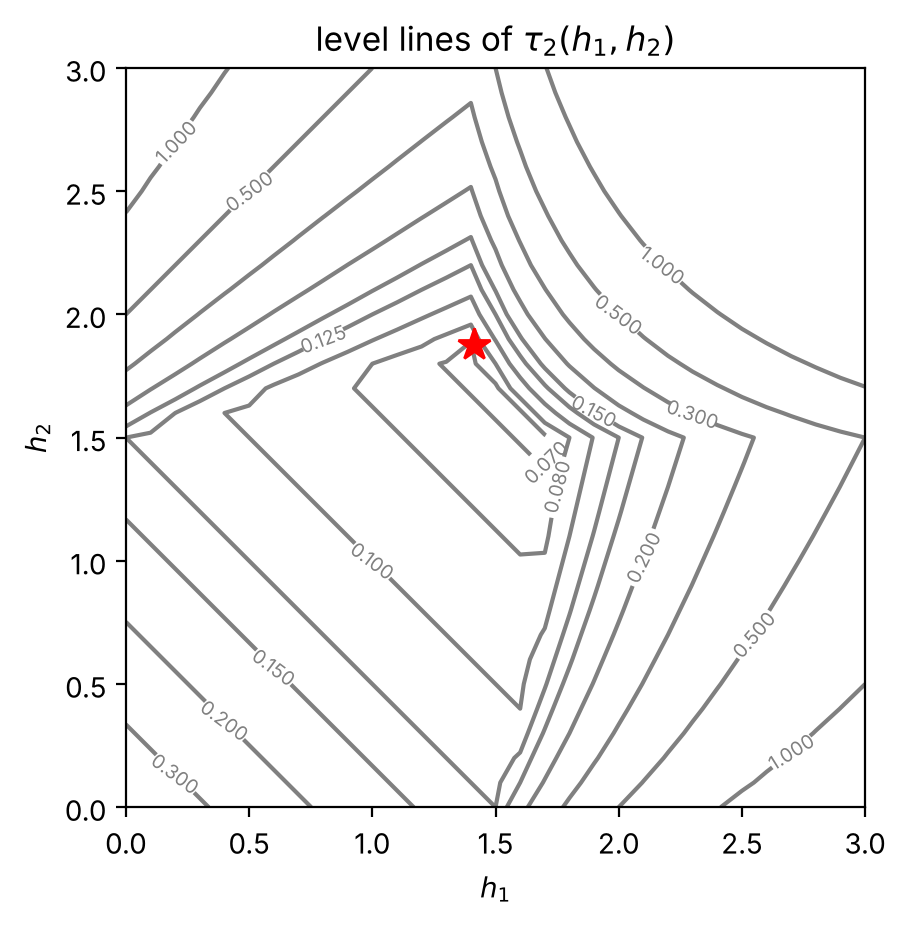

In [5]:
import sympy as sp

def tau_two_step(h1, h2, L=1.0):
    tau, _ = wc_fixed_step([[h1], [h1, h2]], L=L)
    return tau

h = sp.Symbol('h')
s2 = np.sqrt(2)
h2_star = float(sp.nsolve((h - 1) ** 2 * (2 * h + 1 + 2 * sp.sqrt(2)) - (3 + 2 * sp.sqrt(2)), 1.8))
print(f'optimal pair: h1* = sqrt(2) = {s2:.4f}, h2* = {h2_star:.4f}, tau_2 = {tau_two_step(s2, h2_star):.5f}')
print(f'gradient descent (1, 1): tau_2 = {tau_two_step(1, 1):.5f} = 1/10;  swapped pair (h2*, sqrt2): tau_2 = {tau_two_step(h2_star, s2):.5f}')

hs = np.linspace(0.0, 3.0, 31)
T = np.array([[tau_two_step(a, b) for b in hs] for a in hs])   # about a minute
H1, H2 = np.meshgrid(hs, hs, indexing='ij')
cs = plt.contour(H1, H2, T, levels=[0.07, 0.08, 0.1, 0.125, 0.15, 0.2, 0.3, 0.5, 1.0], colors='gray')
plt.clabel(cs, fontsize=7)
plt.plot(s2, h2_star, 'r*', markersize=12)
plt.gca().set_aspect('equal'); plt.xlabel(r'$h_1$'); plt.ylabel(r'$h_2$'); plt.title(r'level lines of $\tau_2(h_1,h_2)$')
plt.show()

### 2.2 Joint optimization

The axis $h_2=0$ is the one-step problem, $\tau_1(h)=\max\{\tfrac12(1-h)^2,\tfrac1{4h+2}\}$, minimized at $h=3/2$: neither $h_1^\star$ nor $h_2^\star$ is the best single step, and choosing the first step as the best single step before optimizing the second one (a greedy choice) gives a worse guarantee than the joint optimum.

In [6]:
from scipy.optimize import minimize_scalar

tau1 = lambda h: max(0.5 * (1 - h) ** 2, 1 / (4 * h + 2))
hs1 = np.linspace(0.5, 2.5, 21)
print('one-step problem: max |PEPit - formula| on a grid =', max(abs(tau_two_step(a, 0.0) - tau1(a)) for a in hs1))
print(f'best single step: h = 3/2, tau_1 = {tau1(1.5):.5f} = 1/8')
greedy = minimize_scalar(lambda b: tau_two_step(1.5, b), bounds=(0.5, 3.0), method='bounded')
print(f'greedy: h1 = 3/2 then best h2 = {greedy.x:.4f}, tau_2 = {greedy.fun:.5f}   vs   joint optimum tau_2 = {tau_two_step(s2, h2_star):.5f}')

one-step problem: max |PEPit - formula| on a grid = 1.009439962773584e-05
best single step: h = 3/2, tau_1 = 0.12500 = 1/8


/usr/local/lib/python3.13/site-packages/PEPit/wrappers/cvxpy_wrapper.py:297: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  self.prob.solve(**kwargs)


greedy: h1 = 3/2 then best h2 = 1.7323, tau_2 = 0.06698   vs   joint optimum tau_2 = 0.06595


### 2.3 The potential inequality

Theorem 5.1 certifies $\Phi_{k+2}\leq\Phi_k$ with the increment $A_{k+2}-A_k=h_1+h_2$ for the potential $\Phi_k=A_k(f(x_k)-f_\star)+\tfrac L2\|x_k-x_\star\|^2$ on the region $h_1\leq\sqrt2$, $(h_2-1)^2(1+h_1+h_2)\leq(1+h_1)^2$. The largest total step size on this region is at $h_1=\sqrt2$ and $h_2$ the root of $(h_2-1)^2(h_2+1+\sqrt2)=3+2\sqrt2$. With PEPit, the worst case of $\Phi_{k+2}$ under $\Phi_k\leq1$ must be at most $1$ for every $A_k$; it is exactly $1$ at this pair, and the inequality fails as soon as the increment is increased.

In [7]:
h2_sharp = float(sp.nsolve((h - 1) ** 2 * (h + 1 + sp.sqrt(2)) - (3 + 2 * sp.sqrt(2)), 2.1))
delta_sharp = s2 + h2_sharp
print(f'h2 = {h2_sharp:.5f},  increment sqrt2 + h2 = {delta_sharp:.5f}  (gradient descent: 2)')

def wc_potential_two_step(h1, h2, Ak, increment, L=1.0):
    '''Worst case of Phi_{k+2} with A_{k+2} = A_k + increment, under Phi_k <= 1 (at most 1 when the inequality holds).'''
    problem = PEP()
    f = problem.declare_function(SmoothConvexFunction, L=L)
    xs = f.stationary_point(); fs = f(xs)
    x = problem.set_initial_point()
    problem.set_initial_condition(Ak * (f(x) - fs) + L / 2 * (x - xs) ** 2 <= 1)
    x1 = x - h1 / L * f.gradient(x)
    x2 = x1 - h2 / L * f.gradient(x1)
    problem.set_performance_metric((Ak + increment) * (f(x2) - fs) + L / 2 * (x2 - xs) ** 2)
    return problem.solve(verbose=0)

for Ak in [0.0, 1.0, 5.0, 20.0]:
    print(f'A_k = {Ak:5.1f}: worst case of Phi_(k+2) under Phi_k <= 1:', round(wc_potential_two_step(s2, h2_sharp, Ak, delta_sharp), 6),
          '| with the increment + 0.05:', round(wc_potential_two_step(s2, h2_sharp, Ak, delta_sharp + 0.05), 6))

h2 = 2.13224,  increment sqrt2 + h2 = 3.54646  (gradient descent: 2)
A_k =   0.0: worst case of Phi_(k+2) under Phi_k <= 1: 1.000001 | with the increment + 0.05: 1.011003
A_k =   1.0: worst case of Phi_(k+2) under Phi_k <= 1: 0.999996 | with the increment + 0.05: 1.000105
A_k =   5.0: worst case of Phi_(k+2) under Phi_k <= 1: 0.999981 | with the increment + 0.05: 1.000051
A_k =  20.0: worst case of Phi_(k+2) under Phi_k <= 1: 1.000002 | with the increment + 0.05: 1.000015


The largest increment $\delta(h_1,h_2)=\inf_{A_k\geq0}\sup\{A_{k+2}-A_k:\Phi_{k+2}\leq\Phi_k\ \text{for all } f\}$ can be computed for every pair by a small semidefinite program (the dual of the worst-case problem, with the increment as a variable, see `code/pep_two_step_lyapunov.py`); a compact version with `cvxpy` is below. On the region of Theorem 5.1 (below the dashed curve), $\delta(h_1,h_2)=h_1+h_2$: the theorem is tight there.

GD (1,1): 2.0 | pair of Section 5.2: 3.54646 = 3.54646 | optimal pair for the final guarantee: 3.29098 = 3.29098


/tmp/ipykernel_881/3302586391.py:22: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  prob.solve(solver='CLARABEL')


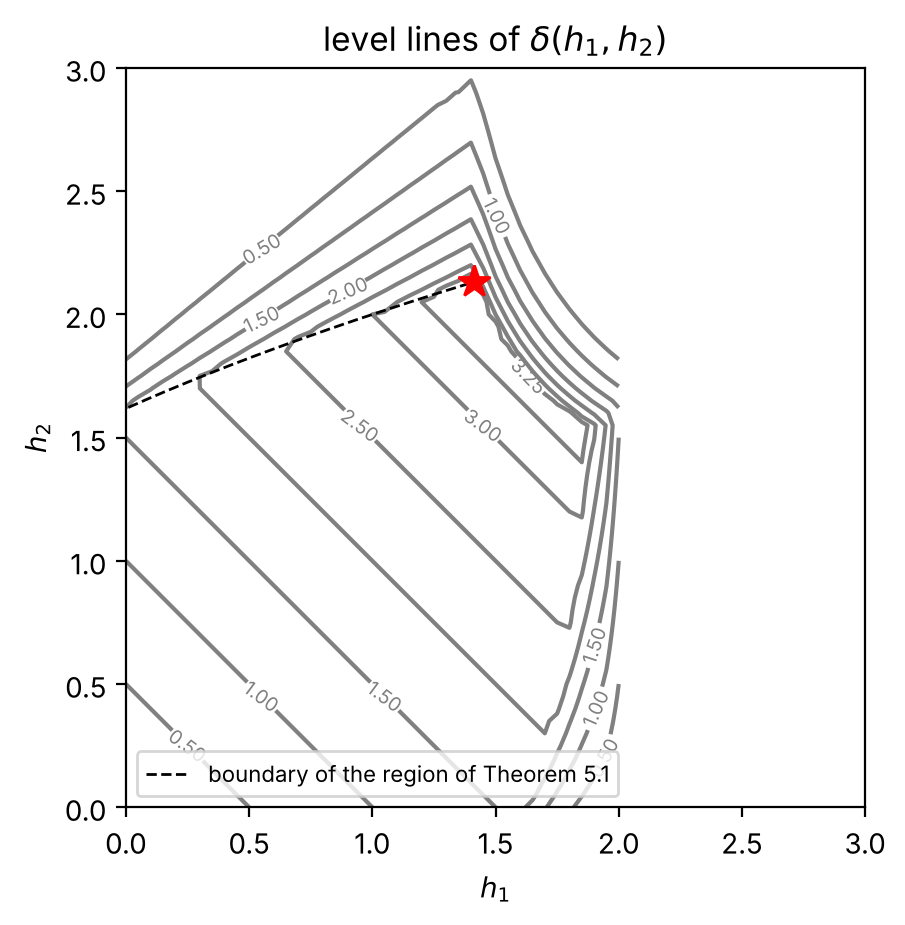

In [8]:
import cvxpy as cp

def increment_two_step(Ak, h1, h2):
    '''Largest increment A_{k+2} - A_k such that Phi_{k+2} <= Phi_k holds for all f in F_{0,1} (L = 1), as an SDP:
    the inequality must be certified by a weighted sum of the interpolation inequalities between x_k, x_{k+1}, x_{k+2}, x_*
    (strong duality makes this exact).  Returns nan when no increment is admissible.'''
    E = np.eye(4)                      # basis: x_k - x_*, g_k, g_{k+1}, g_{k+2}
    pts = {'s': (0 * E[0], 0 * E[0]), 0: (E[0], E[1]), 1: (E[0] - h1 * E[1], E[2]), 2: (E[0] - h1 * E[1] - h2 * E[2], E[3])}
    fidx = {'s': 0, 0: 1, 1: 2, 2: 3}
    sym = lambda u, v: 0.5 * (np.outer(u, v) + np.outer(v, u))
    pairs = [(i, j) for i in pts for j in pts if i != j]
    lam = cp.Variable(len(pairs), nonneg=True)
    B = cp.Variable()                  # A_{k+2}
    Q = 0.5 * sym(pts[0][0], pts[0][0]) - 0.5 * sym(pts[2][0], pts[2][0])     # distance terms of Phi_k - Phi_{k+2}
    lin = np.zeros(4, dtype=object); lin[1] = Ak; lin[3] = -B                 # function-value coefficients (f_*, f_k, f_{k+1}, f_{k+2})
    for n_, (i, j) in enumerate(pairs):
        xi, gi = pts[i]; xj, gj = pts[j]
        Q = Q - lam[n_] * (-sym(gj, xi - xj) - 0.5 * sym(gi - gj, gi - gj))   # quadratic part of the slack of inequality (i, j)
        lin[fidx[i]] = lin[fidx[i]] - lam[n_]; lin[fidx[j]] = lin[fidx[j]] + lam[n_]
    prob = cp.Problem(cp.Maximize(B), [Q >> 0, lin[1] == 0, lin[2] == 0, lin[3] == 0])
    try:
        prob.solve(solver='CLARABEL')
    except cp.error.SolverError:
        return np.nan
    return prob.value - Ak if prob.status in ('optimal', 'optimal_inaccurate') else np.nan

print('GD (1,1):', round(increment_two_step(0, 1, 1), 5), '| pair of Section 5.2:', round(increment_two_step(0, s2, h2_sharp), 5), '=', round(delta_sharp, 5),
      '| optimal pair for the final guarantee:', round(increment_two_step(0, s2, h2_star), 5), '=', round(s2 + h2_star, 5))

hs2 = np.linspace(0.0, 3.0, 61)
def guaranteed_increment(a, b):
    vals = [increment_two_step(A, a, b) for A in (0.0, 2.0, 20.0)]       # infimum over A_k, numerically
    return np.nan if np.any(np.isnan(vals)) else min(vals)

D = np.array([[guaranteed_increment(a, b) for b in hs2] for a in hs2])  # about a minute
H1, H2 = np.meshgrid(hs2, hs2, indexing='ij')
cs = plt.contour(H1, H2, np.ma.masked_invalid(D), levels=[0.5, 1, 1.5, 2, 2.5, 3, 3.25, 3.5], colors='gray')
plt.clabel(cs, fontsize=7)
h1c = np.linspace(0.01, s2, 200)
h2c = [float(sp.nsolve((h - 1) ** 2 * (1 + a + h) - (1 + a) ** 2, 2.0)) for a in h1c]
plt.plot(h1c, h2c, 'k--', linewidth=1, label='boundary of the region of Theorem 5.1')
plt.plot(s2, h2_sharp, 'r*', markersize=12)
plt.gca().set_aspect('equal'); plt.xlabel(r'$h_1$'); plt.ylabel(r'$h_2$'); plt.title(r'level lines of $\delta(h_1,h_2)$'); plt.legend(loc='lower left', fontsize=8)
plt.show()

### 2.4 Iterating the two steps

Corollary 5.2 gives $f(x_N)-f_\star\leq L\|x_0-x_\star\|^2/((h_1+h_2)N)$ for even $N$, an improvement of the constant of gradient descent by the factor $2/(h_1+h_2)$. As for gradient descent, the exact worst case of the iterated method is better than the potential bound.

In [9]:
def H_alternating(N, h1, h2):
    steps = [h1 if k % 2 == 0 else h2 for k in range(N)]
    return [steps[:k] for k in range(1, N + 1)]

print(' N | iterated pair: PEPit | potential bound 1/((h1+h2) N) | GD: exact 1/(4N+2) | GD: potential 1/(2N)')
for N in [2, 4, 6, 8]:
    tau, _ = wc_fixed_step(H_alternating(N, s2, h2_sharp))
    print(f'{N:2d} | {tau:.5f}              | {1/(delta_sharp*N):.5f}                      | {1/(4*N+2):.5f}            | {1/(2*N):.5f}')

 N | iterated pair: PEPit | potential bound 1/((h1+h2) N) | GD: exact 1/(4N+2) | GD: potential 1/(2N)
 2 | 0.10998              | 0.14099                      | 0.10000            | 0.25000
 4 | 0.03293              | 0.07049                      | 0.05556            | 0.12500
 6 | 0.02244              | 0.04700                      | 0.03846            | 0.08333


 8 | 0.01702              | 0.03525                      | 0.02941            | 0.06250


<div align="right"><a href="#toc">↩ Back to TOC</a></div>

## 3. The optimized gradient method <a class="anchor" id="part3"></a>

Minimizing $\tau_N(h)$ over all fixed-step methods gives the optimized gradient method (OGM). In the three-sequence form of the manuscript, $a_k=1+\sqrt{1+2A_k}$, $A_{k+1}=A_k+a_k$ (so that $a_k^2=2A_{k+1}$, twice Nesterov's increments), $y_k=\tfrac{A_k}{A_{k+1}}x_k+\tfrac{a_k}{A_{k+1}}z_k$, $x_{k+1}=y_k-\tfrac1L\nabla f(y_k)$, $z_{k+1}=z_k-\tfrac{a_k}{L}\nabla f(y_k)$, and the output is $y_N=\tfrac{A_N}{A_N+a_N}x_N+\tfrac{a_N}{A_N+a_N}z_N$ with $a_N=\tfrac{1+\sqrt{1+4A_N}}2$. The guarantee $f(y_N)-f_\star\leq\tfrac{L\|x_0-x_\star\|^2}{2(A_N+a_N)}$ is exactly the worst case returned by PEPit.

In [10]:
def ogm_constants(N):
    A = 0.0
    for k in range(N):
        A = A + 1 + np.sqrt(1 + 2 * A)
    a = (1 + np.sqrt(1 + 4 * A)) / 2
    return A, a                                   # A_N and a_N

def wc_ogm(N, L=1.0):
    problem = PEP()
    f = problem.declare_function(SmoothConvexFunction, L=L)
    xs = f.stationary_point(); fs = f(xs)
    x0 = problem.set_initial_point()
    problem.set_initial_condition((x0 - xs) ** 2 <= 1)
    A, x, z = 0.0, x0, x0
    for k in range(N):
        a = 1 + np.sqrt(1 + 2 * A)
        y = (A * x + a * z) / (A + a) if k > 0 else x0
        g = f.gradient(y)
        x, z, A = y - g / L, z - a * g / L, A + a
    a = (1 + np.sqrt(1 + 4 * A)) / 2              # last step
    y = (A * x + a * z) / (A + a)
    problem.set_performance_metric(f(y) - fs)
    return problem.solve(verbose=0)

for N in range(1, 7):
    A, a = ogm_constants(N)
    print(f'N={N}: OGM {wc_ogm(N):.6f}  vs  1/(2(A_N+a_N)) = {1/(2*(A+a)):.6f}  <=  1/(N+1)^2 = {1/(N+1)**2:.6f}   | Nesterov {wc_fixed_step(H_nesterov(N))[0]:.6f}   | GD {1/(4*N+2):.6f}')

N=1: OGM 0.125001  vs  1/(2(A_N+a_N)) = 0.125000  <=  1/(N+1)^2 = 0.250000   | Nesterov 0.166667   | GD 0.166667
N=2: OGM 0.061894  vs  1/(2(A_N+a_N)) = 0.061894  <=  1/(N+1)^2 = 0.111111   | Nesterov 0.100000   | GD 0.100000
N=3: OGM 0.037692  vs  1/(2(A_N+a_N)) = 0.037692  <=  1/(N+1)^2 = 0.062500   | Nesterov 0.066107   | GD 0.071429
N=4: OGM 0.025584  vs  1/(2(A_N+a_N)) = 0.025584  <=  1/(N+1)^2 = 0.040000   | Nesterov 0.046833   | GD 0.055556


N=5: OGM 0.018588  vs  1/(2(A_N+a_N)) = 0.018588  <=  1/(N+1)^2 = 0.027778   | Nesterov 0.034894   | GD 0.045455
N=6: OGM 0.014156  vs  1/(2(A_N+a_N)) = 0.014156  <=  1/(N+1)^2 = 0.020408   | Nesterov 0.027003   | GD 0.038462


<div align="right"><a href="#toc">↩ Back to TOC</a></div>

## 4. Gradient norms <a class="anchor" id="part4"></a>

For the final gradient norm, the natural assumption on the initial point is $f(x_0)-f_\star\leq D$, and the optimized method is OGM-G (Section 5.5), whose coefficients are those of OGM read backwards (in terms of $\theta_k=a_k/2$ for $k<N$ and $\theta_N=a_N$), with the guarantee $\|\nabla f(y_N)\|^2\leq\tfrac{2L(f(x_0)-f_\star)}{A_N+a_N}$. Gradient descent is also computed for comparison (Corollary 5.6 bounds the final gradient norm from the initial distance; from the initial gap, its worst case is the one shown below).

In [11]:
def thetas(N):
    th = [1.0]
    for i in range(1, N):
        th.append((1 + np.sqrt(1 + 4 * th[-1] ** 2)) / 2)
    th.append((1 + np.sqrt(1 + 8 * th[-1] ** 2)) / 2)      # theta_N = a_N (last step)
    return th

def wc_ogmg(N, L=1.0):
    th = thetas(N)
    problem = PEP()
    f = problem.declare_function(SmoothConvexFunction, L=L)
    xs = f.stationary_point(); fs = f(xs)
    x0 = problem.set_initial_point()
    problem.set_initial_condition(f(x0) - fs <= 1)
    x, y = x0, x0
    for k in range(N):
        xnew = y - f.gradient(y) / L
        t1, t0 = th[N - k], th[N - k - 1]
        ynew = xnew + (t1 - 1) * (2 * t0 - 1) / (t1 * (2 * t1 - 1)) * (xnew - x) + (2 * t0 - 1) / (2 * t1 - 1) * (xnew - y)
        x, y = xnew, ynew
    problem.set_performance_metric(f.gradient(y) ** 2)
    return problem.solve(verbose=0)

def wc_gd_gradnorm(N, L=1.0, initial='gap'):
    problem = PEP()
    f = problem.declare_function(SmoothConvexFunction, L=L)
    xs = f.stationary_point(); fs = f(xs)
    x = problem.set_initial_point()
    problem.set_initial_condition(f(x) - fs <= 1 if initial == 'gap' else (x - xs) ** 2 <= 1)
    for k in range(N):
        x = x - f.gradient(x) / L
    problem.set_performance_metric(f.gradient(x) ** 2)
    return problem.solve(verbose=0)

for N in range(1, 7):
    A, a = ogm_constants(N)
    print(f'N={N}: OGM-G {wc_ogmg(N):.6f}  vs  2/(A_N+a_N) = {2/(A+a):.6f} (= 2/theta_N^2 = {2/thetas(N)[-1]**2:.6f})   |  GD from the gap {wc_gd_gradnorm(N):.6f}'
          f'   |  GD from the distance {wc_gd_gradnorm(N, initial="distance"):.6f}  vs  Corollary 5.6: 1/N^2 = {1/N**2:.6f}')

N=1: OGM-G 0.500000  vs  2/(A_N+a_N) = 0.500000 (= 2/theta_N^2 = 0.500000)   |  GD from the gap 0.666667   |  GD from the distance 0.250000  vs  Corollary 5.6: 1/N^2 = 1.000000


N=2: OGM-G 0.247574  vs  2/(A_N+a_N) = 0.247577 (= 2/theta_N^2 = 0.247577)   |  GD from the gap 0.400000   |  GD from the distance 0.111112  vs  Corollary 5.6: 1/N^2 = 0.250000
N=3: OGM-G 0.150770  vs  2/(A_N+a_N) = 0.150770 (= 2/theta_N^2 = 0.150770)   |  GD from the gap 0.285721   |  GD from the distance 0.062500  vs  Corollary 5.6: 1/N^2 = 0.111111


N=4: OGM-G 0.102336  vs  2/(A_N+a_N) = 0.102336 (= 2/theta_N^2 = 0.102336)   |  GD from the gap 0.222224   |  GD from the distance 0.040000  vs  Corollary 5.6: 1/N^2 = 0.062500


N=5: OGM-G 0.074353  vs  2/(A_N+a_N) = 0.074353 (= 2/theta_N^2 = 0.074353)   |  GD from the gap 0.181818   |  GD from the distance 0.027778  vs  Corollary 5.6: 1/N^2 = 0.040000


N=6: OGM-G 0.056625  vs  2/(A_N+a_N) = 0.056624 (= 2/theta_N^2 = 0.056624)   |  GD from the gap 0.153846   |  GD from the distance 0.020408  vs  Corollary 5.6: 1/N^2 = 0.027778


<div align="right"><a href="#toc">↩ Back to TOC</a></div>